# Chapter 33: Oligopoly: Cournot, Bertrand, Capacity, and Leadership

This notebook reruns four worked examples from the chapter: a Cournot duopoly with a cost shock, the cartel deterrence threshold, the Cournot merger paradox and Stackelberg leadership. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def cournot_linear(a, costs):
    """cournot-quantity-competition, cournot-merger-paradox: Cournot equilibrium with P = a - Q.

    Each active firm produces q_i = P - c_i with P = (a + sum of active c_i) / (n + 1); a firm
    whose quantity would be negative is dropped (nonnegativity binds). Book: a = 100,
    costs (10, 10) gives 30, 30, P = 40, profit 900; costs (10, 34) gives 38, 14, P = 48,
    profits 1,444 and 196; a = 70 with six firms at 10 gives 60/7 each and profit 3600/49.
    Returns {"q": [...], "Q", "P", "profits": [...]}.
    """
    costs = [float(c) for c in costs]
    active = list(range(len(costs)))
    while True:
        P = (a + sum(costs[i] for i in active)) / (len(active) + 1)
        drop = [i for i in active if P - costs[i] < 0]
        if not drop:
            break
        active = [i for i in active if i not in drop]
    q = [max(0.0, P - c) if i in active else 0.0 for i, c in enumerate(costs)]
    return {"q": q, "Q": sum(q), "P": P, "profits": [(P - c) * qi for c, qi in zip(costs, q)]}


def cartel_threshold(piC, piD, piP):
    """cartel-instability: delta* = (piD - piC) / (piD - piP). Book: (220 - 120)/(220 - 70) = 2/3."""
    return (piD - piC) / (piD - piP)


def cartel_values(piC, piD, piP, delta, q=1.0):
    """cartel-instability: compliance value, deviation value and the expected punishment loss.

    Book at delta = 0.80: 600 and 500; q delta (piC - piP)/(1 - delta) = 80 at q = 0.40, 120 at 0.60.
    """
    return {"comply": piC / (1 - delta), "deviate": piD + delta * piP / (1 - delta),
            "temptation": piD - piC, "expected_loss": q * delta * (piC - piP) / (1 - delta)}


def stackelberg_linear(a, c, qL):
    """stackelberg-leadership: follower best response to a committed leader output, P = a - Q, cost c.

    q_F = max(0, (a - c - q_L) / 2). Book: a = 100, c = 20, q_L = 40 gives q_F = 20, P = 40,
    profits 800 and 400, consumer surplus 1,800.
    """
    qF = max(0.0, (a - c - qL) / 2)
    Q = qL + qF
    P = a - Q
    return {"qL": qL, "qF": qF, "Q": Q, "P": P, "piL": (P - c) * qL, "piF": (P - c) * qF, "cs": 0.5 * Q * Q}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(cournot_linear=cournot_linear, cartel_threshold=cartel_threshold, cartel_values=cartel_values, stackelberg_linear=stackelberg_linear)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'cournot-quantity-competition': {'a': 100,
                                  'c': 10,
                                  'q': 30,
                                  'P': 40,
                                  'profit': 900,
                                  'cB_2': 34,
                                  'qA_2': 38,
                                  'qB_2': 14,
                                  'P_2': 48,
                                  'piA_2': 1444,
                                  'piB_2': 196,
                                  'monopoly_Q': 45,
                                  'monopoly_P': 55,
                                  'monopoly_profit': 2025},
 'cartel-instability': {'piC': 120,
                        'piD': 220,
                        'piP': 70,
                        'delta': 0.8,
                        'delta_star': 0.667,
                        'comply': 600,
                        'deviate': 500,
                        'q': 0.4,
                        'loss': 80,
                        'q_2': 0.6,
                        'loss_2': 120},
 'cournot-merger-paradox': {'a': 70,
                            'c': 10,
                            'n': 6,
                            'q': 8.57,
                            'P': 18.57,
                            'profit': 73.47,
                            'insiders': 146.94,
                            'merged_q': 10,
                            'merged_P': 20,
                            'merged_profit': 100,
                            'cM_2': 5,
                            'P_2': 19.17,
                            'qM_2': 14.17,
                            'qO_2': 9.17,
                            'merged_profit_2': 200.69},
 'stackelberg-leadership': {'a': 100,
                            'c': 20,
                            'qL': 40,
                            'qF': 20,
                            'P': 40,
                            'piL': 800,
                            'piF': 400,
                            'cournot_q': 26.67,
                            'cournot_P': 46.67,
                            'cournot_profit': 711.11,
                            'cs_cournot': 1422.22,
                            'cs': 1800},
 'constructed': {'cournot-quantity-competition': {'cB': [22, 46]},
                 'cartel-instability': {'delta': [0.6, 0.7, 0.9], 'q': [1.0]},
                 'cournot-merger-paradox': {'cM': [7.5, 2.5]},
                 'stackelberg-leadership': {'qL': [20, 60]}}}


def cournot_picture(cb=10):
    b = BV["cournot-quantity-competition"]
    a, ca = b["a"], b["c"]
    r = industrial.cournot_linear(a, [ca, cb])
    qa, qb = r["q"]
    pa, pb = r["profits"]
    base = industrial.cournot_linear(a, [ca, ca])
    xs = np.linspace(0, 90, 200)
    fig, ax = new_figure()
    ax.plot(xs, np.maximum(0, (a - cb - xs) / 2), color=PALETTE["teal"], linewidth=2.2,
            label=f"Beacon: q_B = ({a - cb} - q_A) / 2")
    ys = np.linspace(0, 90, 200)
    ax.plot(np.maximum(0, (a - ca - ys) / 2), ys, color=PALETTE["navy"], linewidth=2.2,
            label=f"Atlas: q_A = ({a - ca} - q_B) / 2")
    ax.legend(loc="upper right", frameon=False)
    mark(ax, qa, qb, f"({num(qa)}, {num(qb)})", col="terracotta", dx=10, dy=10)
    ax.set_xlim(0, 92)
    ax.set_ylim(0, 92)
    ax.set_xlabel("Atlas output q_A")
    ax.set_ylabel("Beacon output q_B")
    metrics = {"Atlas output q_A": num(qa), "Beacon output q_B": num(qb), "Price P": money(r["P"]),
               "Atlas profit": money(pa), "Beacon profit": money(pb),
               "Change in total output from 60": plus(r["Q"] - base["Q"])}
    steps = [f"P = (100 + 10 + {cb}) / 3 = {num(r['P'])}",
             f"q_A = {num(r['P'])} - 10 = {num(qa)}",
             f"q_B = {num(r['P'])} - {cb} = {num(qb)}",
             f"pi_A = ({num(r['P'])} - 10) x {num(qa)} = {num(pa)}",
             f"pi_B = ({num(r['P'])} - {cb}) x {num(qb)} = {num(pb)}"]
    if cb == ca:
        tail = "Costs are equal, so the firms split output evenly."
    else:
        tail = (f"Compared with equal costs, Atlas expands by {num(qa - 30)} while Beacon contracts by "
                f"{num(30 - qb)}, so Atlas replaces only part of the lost output.")
    interp = (f"Solving the two reaction lines gives P = (100 + 10 + {cb}) / 3 = {num(r['P'])}, q_A = {num(qa)} and "
              f"q_B = {num(qb)}. Profits are {num(pa)} and {num(pb)}. {tail}")
    alt = (f"Reaction lines for Atlas and Beacon cross at q_A = {num(qa)}, q_B = {num(qb)} when Beacon's marginal "
           f"cost is {cb}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cartel_picture(delta=0.80, q=0.40):
    b = BV["cartel-instability"]
    piC, piD, piP = b["piC"], b["piD"], b["piP"]
    star = industrial.cartel_threshold(piC, piD, piP)
    v = industrial.cartel_values(piC, piD, piP, delta, q)
    loss, gain = v["expected_loss"], v["temptation"]
    holds = loss > gain + 1e-9
    tie = abs(loss - gain) <= 1e-9
    fig, ax = new_figure()
    bar_compare(ax, ["temptation", "expected punishment loss"], [gain, loss], colors=["terracotta", "teal"],
                value_labels=[num(gain, 0), num(loss, 0)], ylabel="$ thousand", xlabel="Comparison")
    verdict = ("exactly balanced, so the member is indifferent" if tie else
               ("deterred" if holds else "not deterred"))
    metrics = {"Critical discount factor": num(star, 3), "Compliance value": num(v["comply"], 0),
               "Deviation value (sure detection)": num(v["deviate"], 0), "Temptation": num(gain, 0),
               "Expected punishment loss": num(loss, 0), "Cheating": "Deterred" if holds else (
                   "Indifferent" if tie else "Not deterred")}
    steps = [f"delta* = (220 - 120) / (220 - 70) = {num(star, 3)}",
             f"Comply: 120 / (1 - {num(delta)}) = {num(v['comply'], 0)}",
             f"Deviate: 220 + {num(delta)} x 70 / (1 - {num(delta)}) = {num(v['deviate'], 0)}",
             f"Expected loss = {num(q)} x {num(delta)} x 50 / {num(1 - delta)} = {num(loss, 0)}",
             f"Compare with the temptation 220 - 120 = {num(gain, 0)}"]
    interp = (f"With sure detection, compliance is worth {num(v['comply'], 0)} against {num(v['deviate'], 0)} for "
              f"cheating; delta = {num(delta)} is {'above' if delta > star else 'below'} delta* = {num(star, 3)}. With "
              f"detection probability {num(q)}, the expected loss is {num(q)} x {num(delta)} x 50 / {num(1 - delta)} = "
              f"{num(loss, 0)} against a temptation of {num(gain, 0)}, so cheating is {verdict}.")
    alt = (f"Bars comparing the 100 thousand temptation to cheat with the expected punishment loss of {num(loss, 0)} "
           f"thousand at discount factor {num(delta)} and detection probability {num(q)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def merger_picture(cm=10):
    b = BV["cournot-merger-paradox"]
    a, c = b["a"], b["c"]
    pre = industrial.cournot_linear(a, [c] * 6)
    post = industrial.cournot_linear(a, [cm] + [c] * 4)
    insiders = 2 * pre["profits"][0]
    merged = post["profits"][0]
    gain = merged - insiders
    fig, ax = new_figure()
    bar_compare(ax, ["two insiders before", "merged firm after"], [insiders, merged],
                colors=["grey", "teal" if gain > 0 else "terracotta"],
                value_labels=[money(insiders), money(merged)], ylabel="Profit ($)", xlabel="Ownership")
    hline(ax, insiders, None, col="grey")
    metrics = {"Insiders' profit before": money(insiders), "Merged profit after": money(merged),
               "Gain from merging": plus(gain), "Price before": money(pre["P"]), "Price after": money(post["P"]),
               "Merged output": num(post["q"][0])}
    steps = [f"Before: q = 60 / 7 = {num(pre['q'][0], 4)}, profit {num(pre['profits'][0], 4)} each, "
             f"{num(insiders)} for two",
             f"After: P = (70 + {num(cm, 1)} + 4 x 10) / 6 = {num(post['P'], 4)}",
             f"q_M = {num(post['P'], 4)} - {num(cm, 1)} = {num(post['q'][0], 4)}",
             f"Merged profit = {num(post['q'][0], 4)}^2 = {num(merged)}",
             f"Gain = {num(merged)} - {num(insiders)} = {num(gain)}"]
    verdict = "gain" if gain > 0 else "lose"
    interp = (f"Before the merger each of six firms makes 60/7 = {num(pre['q'][0])} and earns {num(pre['profits'][0])}, "
              f"so the two insiders earn {num(insiders)}. After merging with marginal cost {num(cm, 1)}, price is "
              f"(70 + {num(cm, 1)} + 40) / 6 = {num(post['P'])} and the merged firm earns {num(post['q'][0])}^2 = "
              f"{num(merged)}. The insiders {verdict} {num(abs(gain))}.")
    alt = (f"Bars comparing the two insiders' combined profit before the merger, {money(insiders)}, with the merged "
           f"firm's profit {money(merged)} at merged marginal cost {num(cm, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def stackelberg_picture(ql=40.0):
    b = BV["stackelberg-leadership"]
    a, c = b["a"], b["c"]
    r = industrial.stackelberg_linear(a, c, ql)
    xs = np.linspace(0, 80, 200)
    fig, ax = new_figure()
    ax.plot(xs, xs * (80 - xs) / 2, color=PALETTE["navy"], linewidth=2.2, label="leader profit q_L(80 - q_L)/2")
    ax.plot(xs, ((80 - xs) / 2) ** 2, color=PALETTE["teal"], linewidth=2.0, linestyle="dashed",
            label="follower profit")
    ax.legend(loc="upper right", frameon=False)
    mark(ax, ql, r["piL"], f"leader {num(r['piL'])}", col="terracotta", dx=-8, dy=8, ha="right")
    mark(ax, ql, r["piF"], f"follower {num(r['piF'])}", col="teal", dx=8, dy=8, va="bottom")
    vline(ax, 80 / 3, "Cournot 26.67", col="grey", ha="right", y_frac=0.97)
    ax.set_xlim(0, 82)
    ax.set_ylim(0, 1900)
    ax.set_xlabel("Leader committed output q_L")
    ax.set_ylabel("Profit ($)")
    metrics = {"Follower output q_F": num(r["qF"]), "Price P": money(r["P"]), "Leader profit": money(r["piL"]),
               "Follower profit": money(r["piF"]), "Consumer surplus": money(r["cs"])}
    steps = [f"q_F = (80 - {num(ql)}) / 2 = {num(r['qF'])}",
             f"Q = {num(ql)} + {num(r['qF'])} = {num(r['Q'])}, P = 100 - {num(r['Q'])} = {num(r['P'])}",
             f"pi_L = ({num(r['P'])} - 20) x {num(ql)} = {num(r['piL'])}",
             f"pi_F = ({num(r['P'])} - 20) x {num(r['qF'])} = {num(r['piF'])}",
             f"CS = 0.5 x {num(r['Q'], 4)}^2 = {num(r['cs'])}"]
    best = "the leader's best commitment" if abs(ql - 40) < 1e-9 else (
        "below the 800 the leader earns at 40")
    interp = (f"Committing to {num(ql)} leads the follower to (80 - {num(ql)}) / 2 = {num(r['qF'])}. Price is "
              f"{num(r['P'])}, the leader earns {num(r['piL'])} and the follower {num(r['piF'])}; leader profit is "
              f"{best}. Consumer surplus is {num(r['cs'])}.")
    alt = (f"Leader profit q_L(80 - q_L)/2 peaks at 40. At the committed output {num(ql)} the leader earns "
           f"{num(r['piL'])} and the follower {num(r['piF'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Cournot quantity competition: a cost shock

Atlas and Beacon face $P=100-Q$ and start with marginal cost 10. Raising Beacon's cost to 34 gives

$$q_A=\frac{90-q_B}{2},\qquad q_B=\frac{66-q_A}{2}$$

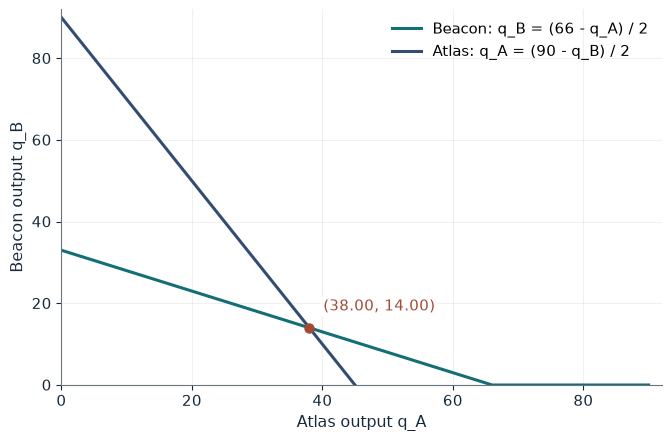

Atlas output q_A                38.00
Beacon output q_B               14.00
Price P                         $48.00
Atlas profit                    $1,444.00
Beacon profit                   $196.00
Change in total output from 60  -8.00

Worked steps:
  1. P = (100 + 10 + 34) / 3 = 48.00
  2. q_A = 48.00 - 10 = 38.00
  3. q_B = 48.00 - 34 = 14.00
  4. pi_A = (48.00 - 10) x 38.00 = 1,444.00
  5. pi_B = (48.00 - 34) x 14.00 = 196.00

Solving the two reaction lines gives P = (100 + 10 + 34) / 3 = 48.00, q_A = 38.00 and q_B = 14.00. Profits are 1,444.00 and 196.00. Compared with equal costs, Atlas expands by 8.00 while Beacon contracts by 16.00, so Atlas replaces only part of the lost output.


In [2]:
show(cournot_picture(cb=34))

Change one input, `cb`, and hold the others at the book's values:

In [3]:
sweep(cournot_picture, 'cb', [10, 22, 34, 46], {}, ['Atlas output q_A', 'Beacon output q_B', 'Price P'])

cb | Atlas output q_A | Beacon output q_B | Price P
10 | 30.00 | 30.00 | $40.00
22 | 34.00 | 22.00 | $44.00
34 | 38.00 | 14.00 | $48.00
46 | 42.00 | 6.00 | $52.00


Beacon cuts 16 units and Atlas adds only 8, so price rises from 40 to 48. Profits become \$1,444 and \$196.

## 2. Cartel instability: when does a cartel hold?

Quota profit is 120, the deviation profit 220 and the punishment profit 70 (thousand per quarter).

$$\delta^*=\frac{220-120}{220-70}=\frac{2}{3}\approx0.667, \qquad \frac{q\delta(\pi^C-\pi^P)}{1-\delta}$$

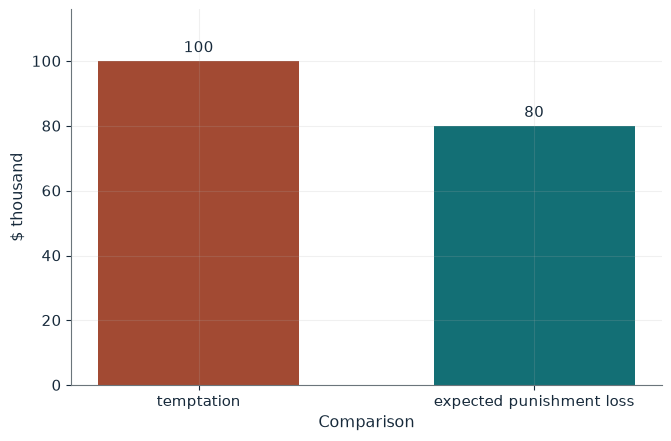

Critical discount factor          0.667
Compliance value                  600
Deviation value (sure detection)  500
Temptation                        100
Expected punishment loss          80
Cheating                          Not deterred

Worked steps:
  1. delta* = (220 - 120) / (220 - 70) = 0.667
  2. Comply: 120 / (1 - 0.80) = 600
  3. Deviate: 220 + 0.80 x 70 / (1 - 0.80) = 500
  4. Expected loss = 0.40 x 0.80 x 50 / 0.20 = 80
  5. Compare with the temptation 220 - 120 = 100

With sure detection, compliance is worth 600 against 500 for cheating; delta = 0.80 is above delta* = 0.667. With detection probability 0.40, the expected loss is 0.40 x 0.80 x 50 / 0.20 = 80 against a temptation of 100, so cheating is not deterred.


In [4]:
show(cartel_picture(delta=0.80, q=0.40))

Change one input, `q`, and hold the others at the book's values:

In [5]:
sweep(cartel_picture, 'q', [0.4, 0.6, 1.0], {'delta': 0.8}, ['Expected punishment loss', 'Cheating'])

q | Expected punishment loss | Cheating
0.4 | 80 | Not deterred
0.6 | 120 | Deterred
1.0 | 200 | Deterred


At delta = 0.80 sure detection deters cheating (600 against 500), but with detection probability 0.40 the expected loss of 80 is below the 100 temptation. Detection of 0.60 restores deterrence.

## 3. Cournot merger paradox

Six firms face $P=70-Q$ with marginal cost 10. Each earns

$$\left(\frac{60}{7}\right)^2=\frac{3600}{49}\approx\$73.47$$

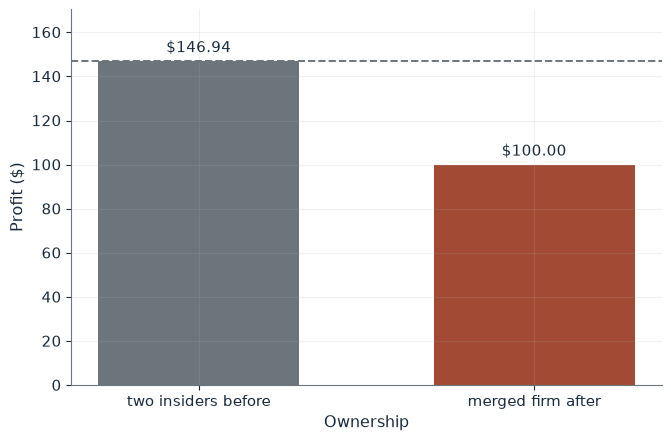

Insiders' profit before  $146.94
Merged profit after      $100.00
Gain from merging        -46.94
Price before             $18.57
Price after              $20.00
Merged output            10.00

Worked steps:
  1. Before: q = 60 / 7 = 8.5714, profit 73.4694 each, 146.94 for two
  2. After: P = (70 + 10.0 + 4 x 10) / 6 = 20.0000
  3. q_M = 20.0000 - 10.0 = 10.0000
  4. Merged profit = 10.0000^2 = 100.00
  5. Gain = 100.00 - 146.94 = -46.94

Before the merger each of six firms makes 60/7 = 8.57 and earns 73.47, so the two insiders earn 146.94. After merging with marginal cost 10.0, price is (70 + 10.0 + 40) / 6 = 20.00 and the merged firm earns 10.00^2 = 100.00. The insiders lose 46.94.


In [6]:
show(merger_picture(cm=10))

Change one input, `cm`, and hold the others at the book's values:

In [7]:
sweep(merger_picture, 'cm', [10, 7.5, 5, 2.5], {}, ['Merged profit after', 'Gain from merging', 'Price after'])

cm | Merged profit after | Gain from merging | Price after
10 | $100.00 | -46.94 | $20.00
7.5 | $146.01 | -0.93 | $19.58
5 | $200.69 | +53.76 | $19.17
2.5 | $264.06 | +117.12 | $18.75


Without a cost saving the merged firm earns \$100, less than the \$146.94 the pair earned apart. A cost of 5 lifts merged profit to \$200.69; a cost of 7.5 still falls just short.

## 4. Stackelberg leadership: the value of commitment

With $P=100-Q$ and cost 20, the follower reacts with

$$R_F(q_L)=\max\left\{0,\frac{80-q_L}{2}\right\}, \qquad \pi_L=\frac{q_L(80-q_L)}{2}$$

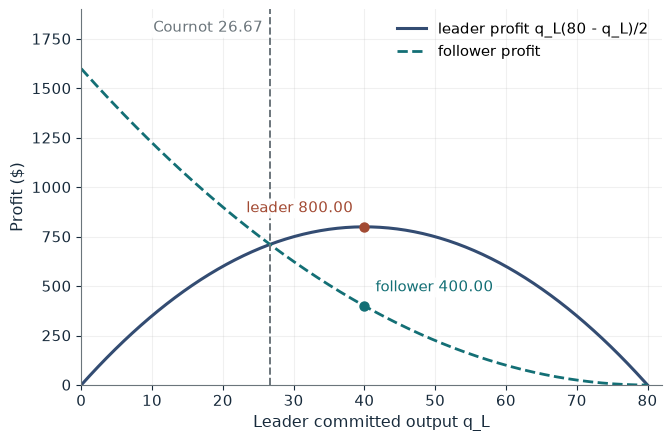

Follower output q_F  20.00
Price P              $40.00
Leader profit        $800.00
Follower profit      $400.00
Consumer surplus     $1,800.00

Worked steps:
  1. q_F = (80 - 40.00) / 2 = 20.00
  2. Q = 40.00 + 20.00 = 60.00, P = 100 - 60.00 = 40.00
  3. pi_L = (40.00 - 20) x 40.00 = 800.00
  4. pi_F = (40.00 - 20) x 20.00 = 400.00
  5. CS = 0.5 x 60.0000^2 = 1,800.00

Committing to 40.00 leads the follower to (80 - 40.00) / 2 = 20.00. Price is 40.00, the leader earns 800.00 and the follower 400.00; leader profit is the leader's best commitment. Consumer surplus is 1,800.00.


In [8]:
show(stackelberg_picture(ql=40.0))

Change one input, `ql`, and hold the others at the book's values:

In [9]:
sweep(stackelberg_picture, 'ql', [20.0, 26.666666666666668, 40.0, 60.0], {}, ['Follower output q_F', 'Leader profit', 'Follower profit'])

ql | Follower output q_F | Leader profit | Follower profit
20.0 | 30.00 | $600.00 | $900.00
26.666666666666668 | 26.67 | $711.11 | $711.11
40.0 | 20.00 | $800.00 | $400.00
60.0 | 10.00 | $600.00 | $100.00


Committing to 40 earns the leader \$800 against \$711.11 under Cournot; committing to 60 is too much and earns \$600.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

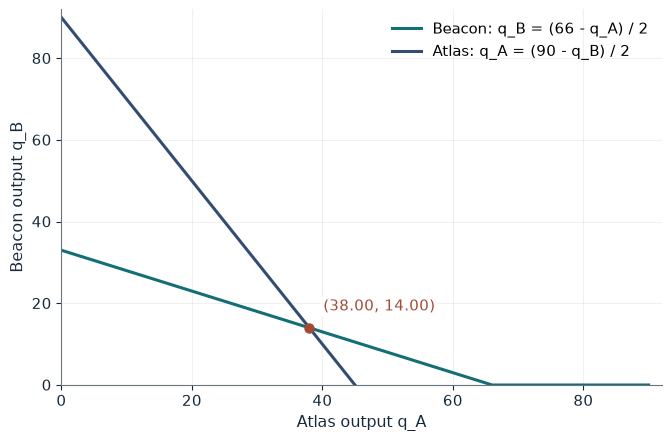

Atlas output q_A                38.00
Beacon output q_B               14.00
Price P                         $48.00
Atlas profit                    $1,444.00
Beacon profit                   $196.00
Change in total output from 60  -8.00

Worked steps:
  1. P = (100 + 10 + 34) / 3 = 48.00
  2. q_A = 48.00 - 10 = 38.00
  3. q_B = 48.00 - 34 = 14.00
  4. pi_A = (48.00 - 10) x 38.00 = 1,444.00
  5. pi_B = (48.00 - 34) x 14.00 = 196.00

Solving the two reaction lines gives P = (100 + 10 + 34) / 3 = 48.00, q_A = 38.00 and q_B = 14.00. Profits are 1,444.00 and 196.00. Compared with equal costs, Atlas expands by 8.00 while Beacon contracts by 16.00, so Atlas replaces only part of the lost output.


In [10]:
show(cournot_picture(cb=34))

## Practice

**1.** At a Beacon cost of 22, what are the quantities and the price?

<details><summary>Answer</summary>

q_A = (100 - 20 + 22) / 3 = 34, q_B = (100 - 44 + 10) / 3 = 22, P = 100 - 56 = 44.

</details>

**2.** At delta = 0.90 and detection probability 0.40, is cheating deterred?

<details><summary>Answer</summary>

0.40 x 0.90 x 50 / 0.10 = 180 > 100, so yes.

</details>

**3.** If the leader commits to 60, what are q_F and the leader's profit?

<details><summary>Answer</summary>

q_F = (80 - 60) / 2 = 10; pi_L = 60 x (80 - 60) / 2 = 600.

</details>